In [1]:
import pandas as pd
import numpy as np
import warnings 
from matplotlib import pyplot as plt
from datetime import datetime
from scipy.linalg import svd
from numpy.linalg import solve
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from IPython.display import display


# FRED-MD Factor Models and Forecasting

This notebook was originally developed as the final project for my Master's course in Advanced Econometrics in 2024. Following McCracken and Ng (2015), I use the FRED-MD panel to estimate common factors and assess their usefulness for forecasting Industrial Production and CPI inflation. The original analysis remains tied to the May 2024 vintage; a separate final section, added in 2026 when revising the project for GitHub, applies the same framework to current FRED-MD data.

# 1) Data import and processing

We import the May 2024 FRED-MD vintage and then organise the information.

In [2]:
# Load data from CSV file
dum = pd.read_csv("2024-05.csv")

In [3]:
# Variable names
series = dum.columns[1:].to_numpy()

In [4]:
# Transformation numbers
tcode = dum.iloc[0, 1:].to_numpy(dtype=int)

In [5]:
# Raw data
rawdata = dum.iloc[1:, 1:].to_numpy(dtype=float)

In [6]:
# Read observation dates directly from the CSV
dates = pd.to_datetime(
    dum.iloc[1:, 0], format="%m/%d/%Y"
).to_numpy()

# Number of monthly observations
T = len(dates)
T

784

We apply transformations to the series to get stationarity, according to the transformation code contained in the dataset.

In [7]:
def prepare_missing(rawdata, tcode):
    """
    Transforms raw data based on each series' transformation code.

    Parameters:
        rawdata (numpy.ndarray): Raw data
        tcode (list or np.ndarray): Transformation codes for each series

    Returns:
        pd.DataFrame: Transformed data
    """
    # Initialize output variable
    yt = pd.DataFrame()

    # Number of series kept
    N = rawdata.shape[1]

    # Perform transformation using subfunction transxf
    for i in range(N):
        dum = transxf(pd.DataFrame(rawdata).iloc[:, i], tcode[i])
        yt = pd.concat([yt, dum], axis=1)

    return yt


def transxf(x, tcode):
    """
    Transforms a single series as specified by a given transformation code.

    Parameters:
        x (pd.Series): Series to be transformed
        tcode (int): Transformation code (1-7)

    Returns:
        pd.Series: Transformed series
    """
    # Number of observations (including missing values)
    n = len(x)

    # Value close to zero
    small = 1e-6

    # Allocate output variable
    y = pd.Series([np.nan] * n)

    # Transformation
    if tcode == 1:  # Level: x(t)
        y = x

    elif tcode == 2:  # First difference
        y = x - x.shift(1)

    elif tcode == 3:  # Second difference
        y = x - 2*x.shift(1) + x.shift(2)

    elif tcode == 4:  # Natural log
        if (x <= small).any():
            y = pd.Series([np.nan] * n)
        else:
            y = np.log(x)

    elif tcode == 5:  # First difference of natural log
        if not (x <= small).any():
            x_log = np.log(x)
            y = x_log - x_log.shift(1)

    elif tcode == 6:  # Second difference of natural log
        if not (x <= small).any():
            x_log = np.log(x)
            y = x_log - 2*x_log.shift(1) + x_log.shift(2)

    elif tcode == 7:  # First difference of percent change
        y = (x/x.shift(1)-1) - (x.shift(1)/x.shift(2)-1)

    return y

In [8]:
yt=prepare_missing(rawdata,tcode)

Consistently with the authors, we drop observations before 03(m)/01(d)/1960.

In [9]:
yt=yt.iloc[14:T,:]
dates=dates[14:T]

We remove the outliers, defined by those observations for which the distance from the median is greater than ten times the interquartile range.

In [10]:
def remove_outliers(X):
    """
    This function takes a set of series aligned in the columns of a matrix
    and replaces outliers with the value NaN.

    Parameters:
    X : pd.DataFrame
        Dataset (one series per column)

    Returns:
    Y : pd.DataFrame
        Dataset with outliers replaced with NaN
    n : pd.Series
        Number of outliers found in each series
    """
    # Calculate median of each series
    median_X = np.nanmedian(X, axis=0)

    # Repeat median of each series over all data points in the series
    median_X_mat = np.tile(median_X, (X.shape[0], 1))

    # Calculate quartiles, ignoring missing values
    Q = np.nanpercentile(X, [25, 50, 75], axis=0)

    # Calculate interquartile range (IQR) of each series
    IQR = Q[2, :] - Q[0, :]

    # Repeat IQR of each series over all data points in the series
    IQR_mat = np.tile(IQR, (X.shape[0], 1))

    # Determine outliers
    Z = np.abs(X - median_X_mat)
    outlier = Z > (10 * IQR_mat)

    # Replace outliers with NaN
    Y = X.copy()
    Y[outlier] = np.nan

    # Count outliers in each series
    n_out = np.sum(outlier, axis=0)

    return Y, n_out

In [11]:
[data,n_out]=remove_outliers(yt)

In [12]:
data = data.reset_index(drop=True)
print(f"The total number of time observations for each of the {data.shape[1]} series is {data.shape[0]}. The number of outliers was {n_out.sum()}.")

The total number of time observations for each of the 126 series is 770. The number of outliers was 159.


# 3) Estimating factors and computing $R^{2}s$. 

Setting parameters of interest for below functions.

In [13]:
#Type of transformation performed on each series before factors are estimated
#  0 --> no transformation
#   1 --> demean only
#   2 --> demean and standardize
#   3 --> recursively demean and then standardize
DEMEAN=2

# Information criterion used to select number of factors, as described in Bai and Ng (2002)
#   1 --> information criterion IC_p1
#   2 --> information criterion IC_p2
#   3 --> information criterion IC_p3
jj=2

# Maximum number of factors to be estimated; if set to 99, the number of factors selected is forced to equal 8
kmax=9

In [14]:
data= data.to_numpy()

We can proceed now to estimate the factors. The chosen method relies on Principal Component analysis, integrated by an algorithm to treat for missing values that follows Stock and Watson (2002).

In the first place, we replace missing values with the mean of the respective distribution. Then we proceed to estimate the factors.
Such estimation comes from a minimimzation of the SSR subject to normalization (first, we have to standardize the series).\
This minimization, mathamatically, would lead to the a set of principal components of order r, whose directions are given by the r eigenvectors of the variance-covariance matrix of X (or correlation matrix, since the series have been standardized) associated with the largest r eigenvalues. The choice of r comes from the minimization of an information criterium as proposed by Bai and Ng (2002).
After the estimation of the factors, we use them to calculate a new value for the missing values, and we repeat until the factor estimates do not change significantly. 

In [15]:
def factors_em(x, kmax, jj, DEMEAN):
    """
    Estimate common factors when some observations are missing.

    Missing values are initially filled with their series mean. The function
    then alternates between PCA estimation and updating the missing values
    with the values predicted by the factors.

    Parameters
    ----------
    x : numpy.ndarray, shape (T, N)
        Transformed data, with months in rows and series in columns.
        Missing observations are represented by np.nan.
    kmax : int
        Maximum number of factors considered by baing.
        The special value 99 forces the use of eight factors.
    jj : int
        Information criterion used by baing: 1, 2 or 3.
    DEMEAN : int
        Data transformation applied before PCA: 0, 1, 2 or 3.

    Returns
    -------
    ehat : numpy.ndarray, shape (T, N)
        Difference between the original data and their reconstruction.
        It remains np.nan where the original data were missing.
    Fhat : numpy.ndarray, shape (T, r)
        Estimated factors, where r is the selected number of factors.
    lamhat : numpy.ndarray, shape (N, r)
        Factor loadings for each series.
    ve2 : numpy.ndarray, shape (N,)
        Eigenvalues of X.T @ X, ordered from largest to smallest.
    x2 : numpy.ndarray, shape (T, N)
        Data in their original scale, with missing values filled in.
    """

    # =========================================================================
    # PART 1: SETUP
    maxit = 100
    T, N = x.shape
    err = 999
    it = 0
    x1 = np.isnan(x)

    # =========================================================================
    # PART 2: INITIALIZE EM ALGORITHM
    mut = np.nanmean(x, axis=0)
    x2 = np.where(np.isnan(x), mut, x)

    x3, mut, sdt = transform_data(x2, DEMEAN)

    if kmax != 99:
        icstar, _, _, _ = baing(x3, kmax, jj)
    else:
        icstar = 8

    chat, Fhat, lamhat, ve2 = pc2(x3, icstar)
    chat0 = chat

    # =========================================================================
    # PART 3: PERFORM EM ALGORITHM
    while err > 0.000001 and it < maxit:
        it += 1
        print(f'Iteration {it}: obj {err:.10f} IC {icstar}')

        # Return the common component to the original scale
        reconstructed = chat * sdt + mut

        # Replace only originally missing observations
        x2 = np.where(x1, reconstructed, x)

        x3, mut, sdt = transform_data(x2, DEMEAN)

        if kmax != 99:
            icstar, _, _, _ = baing(x3, kmax, jj)
        else:
            icstar = 8

        chat, Fhat, lamhat, ve2 = pc2(x3, icstar)

        diff = chat - chat0
        err = np.sum(diff**2) / np.sum(chat0**2)
        chat0 = chat

    if err > 1e-6:
        warnings.warn(
            f"EM did not converge after {it} iterations "
            f"(relative change = {err:.2e}).",
            RuntimeWarning,
            stacklevel=2
        )

    ehat = x - (chat * sdt + mut)

    return ehat, Fhat, lamhat, ve2, x2


def baing(X, kmax, jj):
    """
    Select the number of factors using an information criterion.

    For each possible number of factors from 0 to kmax, the function
    compares the reconstruction error plus a penalty for additional factors.

    Parameters
    ----------
    X : numpy.ndarray, shape (T, N)
        Complete data matrix prepared for PCA.
    kmax : int
        Maximum number of factors to consider.
    jj : int
        Penalty formula to use: 1, 2 or 3.

    Returns
    -------
    ic1 : int
        Number of factors minimizing the information criterion.
    chat : numpy.ndarray, shape (T, N)
        Reconstruction of X using kmax factors.
    Fhat : numpy.ndarray, shape (T, kmax)
        Factors calculated using kmax components.
    eigval : numpy.ndarray, shape (min(T, N),)
        Eigenvalues from the PCA decomposition.
    """

    T, N = X.shape
    NT = N * T
    NT1 = N + T

    ii = np.arange(1, kmax + 1)
    GCT = min(N, T)

    if jj == 1:
        CT = np.log(NT / NT1) * ii * NT1 / NT
    elif jj == 2:
        CT = (NT1 / NT) * np.log(GCT) * ii
    elif jj == 3:
        CT = ii * np.log(GCT) / GCT

    # PCA using the smaller covariance-type matrix
    if T < N:
        ev, eigval, _ = np.linalg.svd(X @ X.T)
        Fhat0 = np.sqrt(T) * ev
        Lambda0 = X.T @ Fhat0 / T
    else:
        ev, eigval, _ = np.linalg.svd(X.T @ X)
        Lambda0 = np.sqrt(N) * ev
        Fhat0 = X @ Lambda0 / N

    Sigma = np.zeros(kmax + 1)
    IC1 = np.zeros((1, kmax + 1))

    # Criterion for 1, 2, ..., kmax factors
    for i in range(kmax, 0, -1):
        Fhat = Fhat0[:, :i]
        lambda_ = Lambda0[:, :i]
        chat = Fhat @ lambda_.T
        ehat = X - chat

        Sigma[i] = np.mean(np.sum(ehat**2 / T, axis=0))
        IC1[:, i] = np.log(Sigma[i]) + CT[i - 1]

    # Criterion with zero factors
    Sigma[0] = np.mean(np.sum(X**2 / T, axis=0))
    IC1[:, 0] = np.log(Sigma[0])

    ic1 = np.argmin(IC1)

    Fhat = Fhat0[:, :kmax]
    Lambda = Lambda0[:, :kmax]
    chat = Fhat @ Lambda.T

    return ic1, chat, Fhat, eigval


def pc2(X, nfac):
    """
    Estimate a given number of factors by principal component analysis.

    Parameters
    ----------
    X : numpy.ndarray, shape (T, N)
        Complete data matrix prepared for PCA.
    nfac : int
        Number of factors to estimate.

    Returns
    -------
    chat : numpy.ndarray, shape (T, N)
        Common component reconstructed using nfac factors.
    fhat : numpy.ndarray, shape (T, nfac)
        Estimated factors.
    lambda_ : numpy.ndarray, shape (N, nfac)
        Factor loadings.
    S : numpy.ndarray, shape (N,)
        Eigenvalues of X.T @ X, ordered from largest to smallest.
    """

    N = X.shape[1]

    # Principal directions and corresponding eigenvalues
    U, S, _ = np.linalg.svd(X.T @ X)

    lambda_ = U[:, :nfac] * np.sqrt(N)
    fhat = X @ lambda_ / N
    chat = fhat @ lambda_.T

    return chat, fhat, lambda_, S


def transform_data(x2, DEMEAN):
    """
    Prepare each series for PCA according to the selected transformation.

    Parameters
    ----------
    x2 : numpy.ndarray, shape (T, N)
        Complete data matrix, with months in rows and series in columns.
    DEMEAN : int
        0: leave the data unchanged;
        1: subtract each series' mean;
        2: subtract its mean and divide by its standard deviation;
        3: subtract its mean calculated progressively through time,
           then divide by its full-sample standard deviation.

    Returns
    -------
    x22 : numpy.ndarray, shape (T, N)
        Data after the selected transformation.
    mut : numpy.ndarray
        Means subtracted from the data. Shape (N,) for DEMEAN 0, 1 or 2;
        shape (T, N) for DEMEAN 3.
    sdt : numpy.ndarray, shape (N,)
        Divisors used in the transformation; ones when no scaling is used.
    """

    T, N = x2.shape

    if DEMEAN == 0:
        mut = np.zeros(N)
        sdt = np.ones(N)
        x22 = x2

    elif DEMEAN == 1:
        mut = np.mean(x2, axis=0)
        sdt = np.ones(N)
        x22 = x2 - mut

    elif DEMEAN == 2:
        mut = np.mean(x2, axis=0)
        sdt = np.std(x2, axis=0, ddof=1)
        x22 = (x2 - mut) / sdt

    elif DEMEAN == 3:
        mut = np.zeros((T, N))

        for t in range(T):
            mut[t, :] = np.mean(x2[:t + 1, :], axis=0)

        sdt = np.std(x2, axis=0, ddof=1)
        x22 = (x2 - mut) / sdt

    return x22, mut, sdt

In [16]:
ehat, Fhat, lamhat, ve2, x2 = factors_em(data, kmax, jj, DEMEAN)

Iteration 1: obj 999.0000000000 IC 7
Iteration 2: obj 0.0053748398 IC 7
Iteration 3: obj 0.0016635809 IC 7
Iteration 4: obj 0.0009592451 IC 7


Iteration 5: obj 0.0006724489 IC 7
Iteration 6: obj 0.0005048138 IC 7
Iteration 7: obj 0.0003924326 IC 7
Iteration 8: obj 0.0003125235 IC 7
Iteration 9: obj 0.0002532881 IC 7
Iteration 10: obj 0.0002077709 IC 7
Iteration 11: obj 0.0001717781 IC 7
Iteration 12: obj 0.0001427416 IC 7
Iteration 13: obj 0.0001190239 IC 7
Iteration 14: obj 0.0000995132 IC 7
Iteration 15: obj 0.0000834008 IC 7
Iteration 16: obj 0.0000700640 IC 7
Iteration 17: obj 0.0000590058 IC 7
Iteration 18: obj 0.0000498216 IC 7
Iteration 19: obj 0.0000421797 IC 7
Iteration 20: obj 0.0000358077 IC 7
Iteration 21: obj 0.0000304819 IC 7
Iteration 22: obj 0.0000260191 IC 7
Iteration 23: obj 0.0000222691 IC 7
Iteration 24: obj 0.0000191094 IC 7
Iteration 25: obj 0.0000164393 IC 7
Iteration 26: obj 0.0000141766 IC 7
Iteration 27: obj 0.0000122537 IC 7
Iteration 28: obj 0.0000106150 IC 7
Iteration 29: obj 0.0000092149 IC 7
Iteration 30: obj 0.0000080154 IC 7
Iteration 31: obj 0.0000069853 IC 7
Iteration 32: obj 0.0000060985 IC

After estimating the factors, we measure how much of each series' variation they explain and identify the series most closely associated with each factor.

In [17]:
def mrsq(Fhat, lamhat, ve2, series):
    """
    Measures how much variation the estimated factors explain.

    Parameters
    ----------
    Fhat : numpy.ndarray, shape (T, r)
        Estimated factors, with one factor per column.
    lamhat : numpy.ndarray, shape (N, r)
        Factor loadings, with one series per row.
    ve2 : numpy.ndarray, shape (N, N)
        Eigenvalues stored on the diagonal of a matrix.
    series : numpy.ndarray, shape (N,)
        Names of the series, in the same order as the rows of lamhat.

    Returns
    -------
    R2 : numpy.ndarray, shape (N, r)
        For each series, variation explained cumulatively by the first
        one, two, ..., r factors.
    mR2 : numpy.ndarray, shape (N, r)
        For each series, variation attributed to each individual factor.
    mR2_F : numpy.ndarray, shape (r, N)
        Shares of total panel variation associated with the selected
        factors, stored in the first r rows of a diagonal matrix.
    R2_T : float
        Share of total panel variation explained by all selected factors.
    t10_s : numpy.ndarray, shape (10, r)
        Names of the ten series most associated with each factor.
    t10_mR2 : numpy.ndarray, shape (10, r)
        Corresponding values of mR2.
    """
    # Number of series and estimated factors
    N, ic = lamhat.shape

    # Results for each series and factor
    R2 = np.empty((N, ic))
    mR2 = np.empty((N, ic))
    t10_s = np.empty((10, ic), dtype=object)
    t10_mR2 = np.empty((10, ic))

    # Add one factor at a time to the common component
    common = np.zeros((Fhat.shape[0], N))

    for i in range(ic):
        component = Fhat[:, i:i+1] @ lamhat[:, i:i+1].T
        common += component

        mR2[:, i] = np.var(component, axis=0, ddof=1)
        R2[:, i] = np.var(common, axis=0, ddof=1)

    # Fraction of total variation explained by the selected factors
    mR2_F = ve2 / np.sum(ve2)
    mR2_F = mR2_F[:ic]
    R2_T = np.sum(mR2_F)

    # Rank series by the contribution of each factor
    sorted_indices = np.argsort(mR2, axis=0)[::-1]

    for i in range(ic):
        top_indices = sorted_indices[:10, i]
        t10_s[:, i] = series[top_indices]
        t10_mR2[:, i] = mR2[top_indices, i]

    return R2, mR2, mR2_F, R2_T, t10_s, t10_mR2


R2, mR2, mR2_F, R2_T, t10_s, t10_mR2 = mrsq(Fhat, lamhat, ve2, series)

In [18]:
print("The total fraction of variance explained by all factors is", R2_T)

The total fraction of variance explained by all factors is 0.4771795963140033


Table 1: Top ten series explained by each factor, by measure of Marginal R-squared.

In [19]:
t10_s = np.asarray(t10_s)

# Number of factors to display
n_factors = 7

# Build the table
table_data = {}

for i in range(n_factors):
    table_data[f"F{i+1} Series"] = t10_s[:, i]
    table_data[f"F{i+1} mR2"] = t10_mR2[:, i]

table_df = pd.DataFrame(table_data)

print(table_df)

   F1 Series    F1 mR2        F2 Series    F2 mR2 F3 Series    F3 mR2  \
0  IPMANSICS  0.807957      CUSR0000SAC  0.591667    BAAFFM  0.440748   
1     PAYEMS  0.780207    CUSR0000SA0L2  0.577879    AAAFFM  0.440472   
2     INDPRO  0.766981  DNDGRG3M086SBEA  0.555405   T10YFFM  0.407031   
3    IPFPNSS  0.758600         CPIAUCSL  0.548037    T5YFFM  0.346840   
4     CUMFNS  0.754057         CPITRNSL  0.534974     HOUST  0.290061   
5     USGOOD  0.743762    CUSR0000SA0L5  0.531170  TB6SMFFM  0.261204   
6    IPFINAL  0.692662            PCEPI  0.510159  TB3SMFFM  0.261188   
7     MANEMP  0.691546         CPIULFSL  0.480649    HOUSTW  0.239890   
8     IPDMAT  0.668005       WPSFD49502  0.418933    PERMIT  0.236505   
9    DMANEMP  0.637292          WPSID61  0.406122   PERMITW  0.234882   

       F4 Series    F4 mR2  F5 Series    F5 mR2      F6 Series    F6 mR2  \
0            GS1  0.612093     T1YFFM  0.519158  CES0600000007  0.373213   
1            GS5  0.604347   TB6SMFFM  0.503

As we can see, factor 1 seems to capture mostly real activity series, as Industrial Production. The real diffusion index is, in fact, based on such factor. However, one must be careful in trying to identify precisly the factors as only linear combinations of factors can be identified.

The computation of the marginal R-squared for each factor allows use to plot a scree plot, a measure of how much each factor can explain tha total variability of the data.

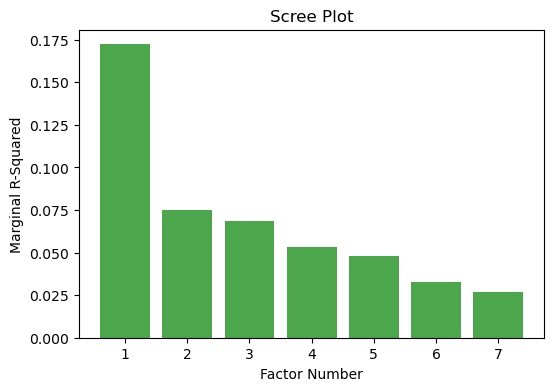

In [20]:
plt.figure(figsize=(6, 4))
plt.bar(range(1, len(mR2_F) + 1), mR2_F, color='g', alpha=0.7)

# Adding titles and labels
plt.title('Scree Plot')
plt.xlabel('Factor Number')
plt.ylabel('Marginal R-Squared')
plt.grid(False)

# Show the plot
plt.show()

Hence, the first factor explains more than 17% of the variability of the data, the second can capture more than 7,5 % and so on. As expected, the marginal R2 for each principal components (i.e. the estimated factors) rapidly collapses after the first factors. That is why the adopted information criterium has led to exclude factors after the seventh, which add little information to the model.

Finally, we plot how much each series in the data set is explained by the 7 factors, i.e. how much the common component can explain the variability of each series.

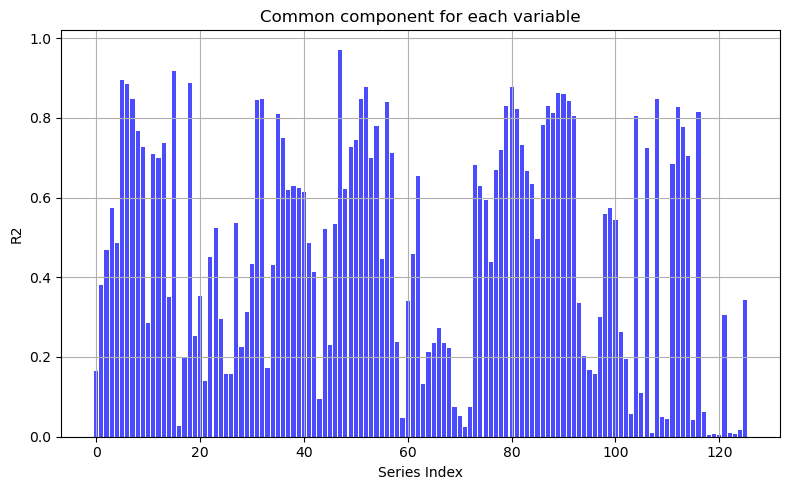

In [21]:
plt.figure(figsize=(8, 5))
total_r2_variables = R2[:,6]
# Plotting the bar chart
plt.bar(np.arange(len(total_r2_variables)), total_r2_variables, color='blue', alpha=0.7)

plt.title('Common component for each variable')
plt.xlabel('Series Index')
plt.ylabel('R2')
plt.grid(True)
plt.tight_layout()

plt.show()

In [22]:
ip_idx = np.where(series == "INDPRO")[0][0]
cpi_idx = np.where(series == "CPIAUCSL")[0][0]

# Convert to NumPy arrays
yt_array = np.asarray(yt)
data_array = np.asarray(data)

# Observations that were present in yt but set to NaN by remove_outliers()
ip_outliers = (~np.isnan(yt_array[:, ip_idx])) & np.isnan(data_array[:, ip_idx])
cpi_outliers = (~np.isnan(yt_array[:, cpi_idx])) & np.isnan(data_array[:, cpi_idx])

print("INDPRO outliers:", ip_outliers.sum())
print("CPIAUCSL outliers:", cpi_outliers.sum())

print("INDPRO outlier dates:", dates[ip_outliers])
print("CPIAUCSL outlier dates:", dates[cpi_outliers])

INDPRO outliers: 1
CPIAUCSL outliers: 0
INDPRO outlier dates: ['2020-04-01T00:00:00.000000000']
CPIAUCSL outlier dates: []


# Part 4: Predictions


We forecast the level of Industrial Production and monthly inflation for the next six months using three specifications: 
1) a **baseline** containing all seven factors prevously deemed optimal by the Bai-Ng criterium; 
2) a **target-specific** model in which BIC also selects the number of factors for each target variable and forecast horizon;
3) an **autoregressive (AR)** benchmark.

For each horizon $h=1,\ldots,6$, we estimate a separate direct regression.

Writing the direct target as $z_{t,h}$, the factor regression is

$$
z_{t,h}=\alpha_h
+\sum_{i=0}^{p-1}\phi_{h,i}y_{t-i}
+\sum_{\ell=0}^{m-1}\beta_{h,\ell}'\hat F^{(q)}_{t-\ell}
+\varepsilon_{t,h}.
$$

The baseline fixes $q=r$, with $r=7$ being the factors selected by Bai-Ng, with the BIC selecting $0\leq p\leq6$ and $1\leq m\leq3$. The target-specific model also lets BIC select $q\in\{1,\ldots,r\}$, the number of ordered principal components included. The AR benchmark selects $p$ independently, without factors. Here, $p$ counts the terms $y_t,\ldots,y_{t-p+1}$, while $m$ counts the factor terms $\hat F_t,\ldots,\hat F_{t-m+1}$; $p=0$ is admissible.

We first estimate all three forecasting regressions over the full usable sample and then repeat the forecasts using the only infomration of the last ten years. However, the factors are unchanged between these two procedures and are estimated from the full panel available at the final forecast origin.


### Forecast settings and common functions


In [23]:
# Settings shared by IP and inflation
max_horizon, p_max, m_max = 6, 6, 3
rolling_window_size = 120
common_start = max(p_max - 1, m_max - 1)

import io
import contextlib


def build_target_factor_predictors(y, factor_data, q, p, m):
    """Predictors using the first q factors and the selected lag orders."""
    columns = {"const": np.ones(len(y))}
    columns.update({f"Y_lag{lag}": y.shift(lag) for lag in range(p)})
    columns.update({
        f"{factor}_lag{lag}": factor_data[factor].shift(lag)
        for factor in factor_data.columns[:q] for lag in range(m)
    })
    return pd.DataFrame(columns, index=y.index)


def build_ar_predictors(y, p):
    """Predictors for the autoregressive benchmark."""
    columns = {"const": np.ones(len(y))}
    columns.update({f"Y_lag{lag}": y.shift(lag) for lag in range(p)})
    return pd.DataFrame(columns, index=y.index)


def cumulative_change_from_series(y, h):
    """Sum the next h values of the stationary change variable."""
    future_changes = pd.concat([y.shift(-j) for j in range(1, h + 1)], axis=1)
    return future_changes.sum(axis=1, min_count=h)


def build_factor_candidates(y, factor_data, q_values=None):
    """Build each lagged series once, then select candidate columns."""
    r = factor_data.shape[1]
    if q_values is None:
        q_values = range(1, r + 1)
    full_X = build_target_factor_predictors(y, factor_data, r, p_max, m_max)
    return {
        (q, p, m): full_X[
            ["const"]
            + [f"Y_lag{lag}" for lag in range(p)]
            + [f"{factor}_lag{lag}"
               for factor in factor_data.columns[:q] for lag in range(m)]
        ]
        for q in q_values for p in range(p_max + 1) for m in range(1, m_max + 1)
    }


def build_ar_candidates(y):
    full_X = build_ar_predictors(y, p_max)
    return {
        p: full_X[["const"] + [f"Y_lag{lag}" for lag in range(p)]]
        for p in range(p_max + 1)
    }


def select_best_model(candidates, target, train_start, train_end):
    """Select the candidate with the lowest BIC on a common training sample."""
    y_train = target.iloc[train_start:train_end].to_numpy()
    best_bic, best_beta, best_X_t, best_order = np.inf, None, None, None

    for order, X in candidates.items():
        X_train = X.iloc[train_start:train_end].to_numpy()
        try:
            beta = np.linalg.solve(X_train.T @ X_train, X_train.T @ y_train)
        except np.linalg.LinAlgError:
            continue

        residuals = y_train - X_train @ beta
        n, k = len(y_train), X_train.shape[1]
        rss = residuals @ residuals
        bic = n * np.log(rss / n) + k * np.log(n)

        if bic < best_bic:
            best_bic, best_beta = bic, beta
            best_X_t, best_order = X.iloc[[-1]].to_numpy(), order

    if best_beta is None:
        raise RuntimeError("No candidate model could be estimated.")
    return (best_X_t @ best_beta).item(), best_order, best_bic


def forecast_models(y, factor_data, window=None, candidates=None):
    """Forecast the three models on the full sample or a fixed-size window."""
    if candidates is None:
        candidates = build_factor_candidates(y, factor_data)
    r = factor_data.shape[1]
    model_candidates = {
        "Baseline": {order: X for order, X in candidates.items() if order[0] == r},
        "Target-specific": candidates,
        "AR": build_ar_candidates(y)
    }
    forecasts = {name: np.empty(max_horizon) for name in model_candidates}
    orders = {name: [] for name in model_candidates}

    for h in range(1, max_horizon + 1):
        target_h = cumulative_change_from_series(y, h)
        train_end = len(y) - h
        train_start = common_start if window is None else train_end - window

        for name, choices in model_candidates.items():
            forecast, order, _ = select_best_model(
                choices, target_h, train_start, train_end
            )
            forecasts[name][h - 1] = forecast
            orders[name].append(order)

    return forecasts, orders


In [24]:
def forecast_specification_table(orders):
    """Report the selected model orders separately from the forecasts."""
    table = pd.concat({
        "Baseline": pd.DataFrame(orders["Baseline"], columns=["q", "p", "m"]),
        "Target-specific": pd.DataFrame(
            orders["Target-specific"], columns=["q", "p", "m"]
        ),
        "AR": pd.DataFrame({"p": orders["AR"]})
    }, axis=1)
    table.index = pd.RangeIndex(1, len(table) + 1, name="Horizon")
    return table


## Industrial Production


For Industrial Production, the stationary predictor is $y_t=\Delta\log(IP_t)$ and the direct target is the cumulative log change

$$
g_{t,h}=\log\left(\frac{IP_{t+h}}{IP_t}\right)
=\sum_{j=1}^{h}\Delta\log(IP_{t+j}).
$$

The predicted change is converted back into the level of the index:

$$
\widehat{IP}_{T+h}=IP_T\exp(\widehat g_{T,h}).
$$


In [25]:
ip_idx = np.where(series == "INDPRO")[0][0]
date_index = pd.DatetimeIndex(dates)
ip_growth = pd.Series(yt.iloc[:, ip_idx].to_numpy(), index=date_index, name="INDPRO_growth")
ip_level = pd.Series(rawdata[-len(date_index):, ip_idx], index=date_index, name="INDPRO")
factors = pd.DataFrame(
    Fhat, index=date_index, columns=[f"F{i+1}" for i in range(Fhat.shape[1])]
)

forecast_origin = ip_level.last_valid_index()
ip_growth = ip_growth.loc[:forecast_origin]
ip_level = ip_level.loc[:forecast_origin]
factors = factors.loc[:forecast_origin]
future_dates = pd.date_range(
    forecast_origin + pd.offsets.MonthBegin(1), periods=max_horizon, freq="MS"
)
ip_candidates = build_factor_candidates(ip_growth, factors)

print(f"Forecast origin: {forecast_origin:%Y-%m} | Observed IP level: {ip_level.loc[forecast_origin]:.3f}")


Forecast origin: 2024-04 | Observed IP level: 102.762


### Six-month forecasts: full-sample regressions


We estimate the baseline, target-specific and AR regressions over the same full usable sample. Recall that the baseline retains all seven factors selected by Bai-Ng and it uses BIC to select the lags of the factor and autoregressive components. 
The target-specific model also lets BIC select the number of factors, at each horizon, while the AR only selects the appropriate autoregressive order.

In [26]:
ip_full_change, ip_full_orders = forecast_models(
    ip_growth, factors, candidates=ip_candidates
)
ip_full_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: ip_level.loc[forecast_origin] * np.exp(change)
       for name, change in ip_full_change.items()}
}, index=future_dates)
ip_full_forecast.index.name = "Date"
display(ip_full_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2024-05-01,1,102.923,102.923,102.911
2024-06-01,2,103.054,103.054,103.107
2024-07-01,3,103.085,103.085,103.298
2024-08-01,4,103.018,102.993,103.669
2024-09-01,5,102.973,102.978,103.884
2024-10-01,6,102.896,102.896,103.876


**Selected specifications by horizon**


In [27]:
display(forecast_specification_table(ip_full_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  0  1               7  0  1  1
2              7  0  1               7  0  1  1
3              7  0  1               7  0  1  1
4              7  0  1               5  0  1  3
5              7  0  1               5  0  1  3
6              7  0  1               7  0  1  1

The baseline and target-specific forecasts are almost identical. BIC retains all seven factors at horizons one, two, three and six, and five factors at horizons four and five; both factor models select $p=0$ and $m=1$ throughout. Selecting fewer factors therefore makes very little difference in this forecast trained on the full sample from 1960.

Both factor models forecast IP close to its April level of 102.762, ending at 102.896 in October. The AR instead forecasts a larger increase at the longer horizons, reaching 103.876 at six months.


### Six-month forecasts: 120-observation regressions


We now estimate the same three regressions using the most recent 120 complete training observations at each horizon. This lets the forecasting coefficients reflect more recent dynamics and uses the same regression window as the rolling evaluation below. The factor estimates remain unchanged, so the comparison with the full-sample forecasts concerns the regression window and the specifications selected within it.


In [28]:
ip_120_change, ip_120_orders = forecast_models(
    ip_growth, factors, window=rolling_window_size, candidates=ip_candidates
)
ip_120_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: ip_level.loc[forecast_origin] * np.exp(change)
       for name, change in ip_120_change.items()}
}, index=future_dates)
ip_120_forecast.index.name = "Date"
display(ip_120_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2024-05-01,1,102.783,102.783,102.737
2024-06-01,2,101.895,102.447,102.730
2024-07-01,3,101.142,102.526,102.747
2024-08-01,4,101.177,102.569,102.767
2024-09-01,5,101.072,102.562,102.828
2024-10-01,6,100.332,102.606,102.851


**Selected specifications by horizon**


In [29]:
display(forecast_specification_table(ip_120_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  1  1               7  1  1  2
2              7  1  1               1  1  1  2
3              7  0  1               1  1  1  2
4              7  1  1               1  1  1  2
5              7  1  1               1  1  1  0
6              7  0  1               1  1  1  0

The shorter regression window produces a more significant separation between the models. The baseline forecasts a substantial fall in IP, reaching 100.332 at six months. The target-specific model selects all seven factors at one month but only the first factor at horizons two to six, producing forecasts much closer to the April level and ending at 102.606. The AR remains near that level throughout, ending at 102.851.

The full-sample and 120-observation tables thus show sensitivity to both the estimation window and factor selection. With the same estimated factors, including all seven in the recent regression leads to a markedly different forecast path. The rolling comparison below evaluates whether these differences translate into lower forecast errors over many historical origins.


### Rolling forecast evaluation


The forecast evaluation is inspired by the comparison between factor and autoregressive models in McCracken and Ng (2015). In their analysis, the predictive contribution of the FRED-MD factors is assessed by comparing factor-augmented regressions with autoregressive models over different out-of-sample periods. Their forecasting regressions are estimated recursively, while the nested comparison keeps the autoregressive structure fixed in order to isolate the additional predictive content of the factors.

Our approach here is slighlty different. We compare all three models over a rolling window of 120 complete regression observations; at each forecast origin, the factor panel is restricted to observations up to that date, the outlier and missing-value procedures are repeated, and the factors are re-estimated over this expanding panel. Bai-Ng selects the available factor number $r_t$. Again the baseline includes all $r_t$ factors, while the target-specific model selects $q\leq r_t$ by means of BIC. Each model selects its own lag orders by BIC on the same regression sample.

For a direct $h$-month forecast made at $t$, the latest complete training target begins at $t-h$. The training window therefore contains 120 usable predictor-target pairs; however, the factors are estimated considering all the information available up to $t$.

Accuracy is measured by

$$
\operatorname{RMSE}_{j,h}
=\sqrt{\frac{1}{n_h}\sum_t
\left(IP_{t+h}-\widehat{IP}^{\,j}_{t+h|t}\right)^2},
\qquad j\in\{Baseline,Target,AR\}.
$$

We report the RMSE ratios **Baseline/AR**, **Target/AR**, and **Target/Baseline**; therefore a ratio below one favours the model in the numerator. These comparisons use the same rolling regression window and forecast origins for all three models.

While this approach resembles a real time evalution insofar as it is aimed at reproducing an econometrician's forecast that makes use only of data known at the time, it is worth to point out that the historical observations come from a single FRED-MD vintage, that may contain revisions and  .

The rolling blocks are the computationally intensive part of the notebook. Set `RUN_EVALUATION = True` to recompute the saved results.


In [30]:
# Set to True to recompute the rolling window evaluations
RUN_EVALUATION = True


In [31]:
# Original transformed panel, before full-sample outlier removal
yt_full = yt.reset_index(drop=True)


def prepare_factor_panel(panel):
    """Prepare the FRED-MD panel available at a given forecast origin."""
    panel = panel.copy().replace([np.inf, -np.inf], np.nan)
    valid_counts = panel.notna().sum()
    panel = panel.loc[:, valid_counts >= 2]
    panel, _ = remove_outliers(panel)
    valid_counts = panel.notna().sum()
    panel = panel.loc[:, valid_counts >= 2]
    variances = panel.var(axis=0, skipna=True, ddof=1)
    return panel.loc[:, variances.notna() & (variances > 1e-12)]


factor_cache = {}


def get_origin_factors(t):
    """Estimate or retrieve the factors available at forecast origin t."""
    if t in factor_cache:
        return factor_cache[t]

    panel_t = prepare_factor_panel(yt_full.iloc[:t + 1].copy())
    n_series_t = panel_t.shape[1]
    kmax_t = min(kmax, panel_t.shape[0] - 1, panel_t.shape[1] - 1)

    with contextlib.redirect_stdout(io.StringIO()):
        _, Fhat_t, _, _, _ = factors_em(panel_t.to_numpy(), kmax_t, jj, DEMEAN)

    n_factors_t = Fhat_t.shape[1]
    if n_factors_t == 0:
        result = (None, n_series_t, 0)
    else:
        factors_t = pd.DataFrame(
            Fhat_t, index=date_index[:t + 1],
            columns=[f"F{i+1}" for i in range(n_factors_t)]
        )
        result = (factors_t, n_series_t, n_factors_t)

    factor_cache[t] = result
    return result


In [32]:
def model_comparison_summary(results, by):
    """Compare the three models using RMSE and pairwise RMSE ratios."""
    errors = results.groupby(by, observed=True).agg(
        Baseline_RMSE=("All-factor Squared Error", "mean"),
        Target_RMSE=("Factor Squared Error", "mean"),
        AR_RMSE=("AR Squared Error", "mean")
    )
    summary = np.sqrt(errors)
    summary["Baseline/AR"] = summary["Baseline_RMSE"] / summary["AR_RMSE"]
    summary["Target/AR"] = summary["Target_RMSE"] / summary["AR_RMSE"]
    summary["Target/Baseline"] = summary["Target_RMSE"] / summary["Baseline_RMSE"]
    return summary


In [33]:
if RUN_EVALUATION:
    rolling_results = []

    # Maximum lag needed by any candidate model
    common_start = max(p_max - 1, m_max - 1)

    # First and last usable forecast origins
    first_origin = common_start + rolling_window_size + max_horizon - 1
    last_origin = len(ip_growth) - max_horizon - 1

    for t in range(first_origin, last_origin + 1):
        # Information available at forecast origin t
        ip_growth_t = ip_growth.iloc[:t + 1]
        factors_t, n_series_t, n_factors_t = get_origin_factors(t)

        if n_factors_t == 0:
            continue

        # Predictor matrices do not depend on h
        factor_candidates = build_factor_candidates(
            ip_growth_t,
            factors_t
        )

        # Same factor space, but with q fixed at all available factors
        all_factor_candidates = {
            order: X
            for order, X in factor_candidates.items()
            if order[0] == n_factors_t
        }
        ar_candidates = build_ar_candidates(ip_growth_t)

        # Forecast h = 1, ..., 6
        for h in range(1, max_horizon + 1):
            y_h = cumulative_change_from_series(ip_growth_t, h)

            # Latest complete target starts at t-h
            train_end = len(ip_growth_t) - h
            train_start = train_end - rolling_window_size

            factor_log_change, best_factor_order, _ = select_best_model(
                factor_candidates,
                y_h,
                train_start,
                train_end
            )
            all_factor_log_change, best_all_factor_order, _ = select_best_model(
                all_factor_candidates,
                y_h,
                train_start,
                train_end
            )
            ar_log_change, best_ar_p, _ = select_best_model(
                ar_candidates,
                y_h,
                train_start,
                train_end
            )

            # Convert forecasts back to INDPRO levels
            factor_forecast = ip_level.iloc[t] * np.exp(factor_log_change)
            all_factor_forecast = ip_level.iloc[t] * np.exp(all_factor_log_change)
            ar_forecast = ip_level.iloc[t] * np.exp(ar_log_change)
            actual = ip_level.iloc[t + h]

            q_selected, p_selected, m_selected = best_factor_order
            _, all_factor_p, all_factor_m = best_all_factor_order

            rolling_results.append({
                "Forecast Origin": ip_level.index[t],
                "Forecast Date": ip_level.index[t + h],
                "Horizon": h,
                "N Series": n_series_t,
                "Available Factors": n_factors_t,
                "Selected q": q_selected,
                "Factor p": p_selected,
                "Factor m": m_selected,
                "All-factor p": all_factor_p,
                "All-factor m": all_factor_m,
                "AR p": best_ar_p,
                "Factor Forecast": factor_forecast,
                "All-factor Forecast": all_factor_forecast,
                "AR Forecast": ar_forecast,
                "Actual": actual,
                "Factor Error": actual - factor_forecast,
                "All-factor Error": actual - all_factor_forecast,
                "AR Error": actual - ar_forecast,
                "Factor Squared Error": (actual - factor_forecast) ** 2,
                "All-factor Squared Error": (actual - all_factor_forecast) ** 2,
                "AR Squared Error": (actual - ar_forecast) ** 2
            })

        # Progress indicator
        if (t - first_origin) % 50 == 0 or t == last_origin:
            print(
                f"Processed forecast origin {t - first_origin + 1} / "
                f"{last_origin - first_origin + 1}"
            )

    rolling_results = pd.DataFrame(rolling_results)
else:
    print("Rolling evaluation skipped. Set RUN_EVALUATION = True to recompute it.")


Processed forecast origin 1 / 634
Processed forecast origin 51 / 634
Processed forecast origin 101 / 634
Processed forecast origin 151 / 634
Processed forecast origin 201 / 634
Processed forecast origin 251 / 634
Processed forecast origin 301 / 634
Processed forecast origin 351 / 634
Processed forecast origin 401 / 634
Processed forecast origin 451 / 634
Processed forecast origin 501 / 634
Processed forecast origin 551 / 634
Processed forecast origin 601 / 634
Processed forecast origin 634 / 634


### Evaluation by forecast horizon


In [34]:
if RUN_EVALUATION:
    rolling_evaluation = model_comparison_summary(rolling_results, "Horizon")
    display(rolling_evaluation.round(3))


,Baseline_RMSE,Target_RMSE,AR_RMSE,Baseline/AR,Target/AR,Target/Baseline
Horizon,,,,,,
1,0.999,1.035,1.127,0.887,0.918,1.036
2,1.227,1.245,1.257,0.976,0.990,1.015
3,1.716,1.564,1.523,1.127,1.027,0.911
4,2.055,1.879,1.845,1.114,1.018,0.914
5,2.217,2.159,2.373,0.934,0.910,0.974
6,2.674,2.609,2.726,0.981,0.957,0.976


There is no single model with the lowest RMSE at every horizon. The baseline performs best at one and two months, the AR at three and four months, and the target-specific model at five and six months. Notably at one month the baseline reduces RMSE by about 11.3% relative to the AR; at five months the target-specific model reduces it by about 9.0%.

Selecting the factor number improves on the baseline most clearly at three and four months, reducing RMSE by about 8.9% and 8.6%, respectively. The AR nevertheless remains more accurate at those two horizons. At one and two months, factor selection slightly raises RMSE relative to the baseline. 


### Evaluation by historical subperiod


We now examine how the results vary across different historical periods.

In [35]:
if RUN_EVALUATION:
    rolling_results["Period"] = pd.cut(
        rolling_results["Forecast Origin"].dt.year,
        bins=[1970, 1989, 2007, 2024],
        labels=["1971-1989", "1990-2007", "2008-2024"]
    )
    period_evaluation = model_comparison_summary(
        rolling_results, ["Period", "Horizon"]
    )
    display(period_evaluation.round(3))


Baseline_RMSE  Target_RMSE  AR_RMSE  Baseline/AR  \
Period    Horizon                                                     
1971-1989 1                0.338        0.351    0.372        0.909   
          2                0.553        0.581    0.636        0.869   
          3                0.763        0.787    0.870        0.877   
          4                0.949        0.975    1.112        0.853   
          5                1.139        1.141    1.352        0.843   
          6                1.289        1.299    1.554        0.830   
1990-2007 1                0.446        0.429    0.443        1.006   
          2                0.651        0.647    0.642        1.014   
          3                0.875        0.845    0.861        1.016   
          4                1.101        1.091    1.095        1.006   
          5                1.311        1.317    1.335        0.982   
          6                1.458        1.478    1.561        0.934   
2008-2024 1                1.723        1.794    1.962        0.878   
          2                2.043        2.071    2.079        0.983   
          3                2.874        2.571    2.447        1.174   
          4                3.411        3.048    2.918        1.169   
          5                3.590        3.468    3.817        0.940   
          6                4.411        4.267    4.374        1.008   

                   Target/AR  Target/Baseline  
Period    Horizon                              
1971-1989 1            0.943            1.037  
          2            0.914            1.051  
          3            0.905            1.031  
          4            0.877            1.028  
          5            0.844            1.002  
          6            0.836            1.008  
1990-2007 1            0.968            0.962  
          2            1.007            0.993  
          3            0.982            0.966  
          4            0.996            0.990  
          5            0.986            1.005  
          6            0.947            1.014  
2008-2024 1            0.914            1.041  
          2            0.996            1.014  
          3            1.050            0.894  
          4            1.044            0.893  
          5            0.908            0.966  
          6            0.976            0.967

The historical breakdown shows that the relative performance changes over time. In 1971-1989, both factor models outperform the AR at every horizon, and the baseline has the lowest RMSE throughout. In 1990-2007, the ratios are generally close to one: the target-specific model performs best at one, three and four months, the AR at two months, and the baseline at five and six months.

In 2008-2024, the baseline performs best at one and two months, the AR at three and four, and the target-specific model at five and six. Factor selection reduces the baseline RMSE by about 10.6% and 10.7% at three and four months, but the AR still has the lowest errors there. At six months, the target-specific model beats both alternatives, while the baseline is slightly worse than the AR. 


### Selection and panel diagnostics


We next examine the specifications selected by BIC and how the factor panel changes across forecast origins.

In [36]:
if RUN_EVALUATION:
    selection_diagnostics = (
        rolling_results
        .groupby("Horizon")
        .agg(
            Mean_Available_Factors=(
                "Available Factors",
                "mean"
            ),
            Mean_Selected_q=(
                "Selected q",
                "mean"
            ),
            Mean_Factor_p=(
                "Factor p",
                "mean"
            ),
            Mean_Factor_m=(
                "Factor m",
                "mean"
            ),
            Mean_AR_p=(
                "AR p",
                "mean"
            )
        )
    )

    display(selection_diagnostics)


,Mean_Available_Factors,Mean_Selected_q,Mean_Factor_p,Mean_Factor_m,Mean_AR_p
Horizon,,,,,
1,6.149842,2.173502,0.228707,1.298107,1.675079
2,6.149842,3.198738,0.831230,1.490536,1.917981
3,6.149842,3.238170,0.580442,1.402208,2.037855
4,6.149842,2.750789,0.842271,1.626183,1.848580
5,6.149842,2.686120,0.834385,1.619874,1.621451
6,6.149842,2.883281,0.823344,1.500000,1.509464


In [37]:
if RUN_EVALUATION:
    panel_diagnostics = (
        rolling_results[
            [
                "Forecast Origin",
                "Period",
                "N Series",
                "Available Factors"
            ]
        ]
        .drop_duplicates(
            subset="Forecast Origin"
        )
        .groupby(
            "Period",
            observed=True
        )
        .agg(
            Min_Series=("N Series", "min"),
            Mean_Series=("N Series", "mean"),
            Max_Series=("N Series", "max"),
            Min_Available_Factors=("Available Factors", "min"),
            Mean_Available_Factors=("Available Factors", "mean"),
            Max_Available_Factors=("Available Factors", "max")
        )
    )

    display(panel_diagnostics)


,Min_Series,Mean_Series,Max_Series,Min_Available_Factors,Mean_Available_Factors,Max_Available_Factors
Period,,,,,,
1971-1989,122,123.508772,124,2,5.346491,6
1990-2007,124,125.805556,126,6,6.027778,7
2008-2024,126,126.000000,126,6,7.252632,8


The composition of the information set changes gradually over time. Even in the earliest evaluation period, at least 122 series are available, while the average number of factors selected by Bai-Ng rises from about 5.3 in 1971-1989 to about 7.3 in 2008-2024.


We now identify the observations for which the factor model performs worst relative to the AR benchmark.

In [38]:

if RUN_EVALUATION:
    # Episodes with the largest target-specific loss relative to the AR
    largest_relative_errors = (
        rolling_results.assign(
            Target_Absolute_Error=lambda x: x["Factor Error"].abs(),
            Baseline_Absolute_Error=lambda x: x["All-factor Error"].abs(),
            AR_Absolute_Error=lambda x: x["AR Error"].abs(),
            Target_AR_AE_Difference=lambda x:
                x["Factor Error"].abs() - x["AR Error"].abs()
        )
        .sort_values("Target_AR_AE_Difference", ascending=False)
    )
    display(largest_relative_errors[[
        "Forecast Origin", "Forecast Date", "Horizon", "Selected q", "Factor p",
        "Actual", "All-factor Forecast", "Factor Forecast", "AR Forecast",
        "Baseline_Absolute_Error", "Target_Absolute_Error", "AR_Absolute_Error",
        "Target_AR_AE_Difference"
    ]].head(20).round(3))


,Forecast Origin,Forecast Date,Horizon,Selected q,Factor p,Actual,All-factor Forecast,Factor Forecast,AR Forecast,Baseline_Absolute_Error,Target_Absolute_Error,AR_Absolute_Error,Target_AR_AE_Difference
2753,2009-03-01,2009-09-01,6,5,0,87.403,76.955,77.240,83.325,10.448,10.164,4.079,6.085
2747,2009-02-01,2009-08-01,6,5,0,86.662,78.847,78.686,83.127,7.815,7.976,3.534,4.441
671,1980-04-01,1980-10-01,6,2,2,50.095,44.341,45.557,49.868,5.754,4.538,0.227,4.311
3710,2022-07-01,2022-10-01,3,2,1,103.411,101.381,99.232,103.266,2.031,4.180,0.146,4.034
2759,2009-04-01,2009-10-01,6,5,0,87.604,78.946,77.964,81.786,8.658,9.639,5.817,3.822
2777,2009-07-01,2010-01-01,6,5,0,89.191,81.327,80.629,84.449,7.864,8.562,4.742,3.820
3757,2023-03-01,2023-05-01,2,7,0,102.924,98.913,98.913,102.727,4.011,4.011,0.197,3.813
2746,2009-02-01,2009-07-01,5,5,0,85.704,80.496,80.282,84.082,5.208,5.423,1.622,3.800
3548,2020-04-01,2020-07-01,3,1,1,95.014,77.449,81.023,84.697,17.566,13.992,10.317,3.674
3677,2022-01-01,2022-07-01,6,3,1,103.133,96.972,97.678,101.264,6.161,5.454,1.868,3.586


For an individual forecast, RMSE equals the absolute error. The table therefore reports the three absolute errors and orders episodes by the target-specific model's absolute error minus the AR's absolute error. 

The largest gaps occure in the months immediately following major unexpected macroeconomic shocks, as the financial crisis of 2008/2009, the 2020 Covid lockdowns and the turbulent years after. This may be due to the fact that in our settings BIC often implies for the factor models the choice $p=0$ (i.e. no lags of the target variable, see both above and table below); consider also the outlier removal procedure before estimating the factors. 

Additional information on the distributions of $p, m$ and $q$ for the target-specific model is provided in the table below. 

In [39]:
if RUN_EVALUATION:
    # Distribution of selected model specifications

    # q distribution
    q_distribution = (
        rolling_results
        .groupby(["Horizon", "Selected q"])
        .size()
        .rename("Count")
        .reset_index()
    )

    q_distribution["Percentage"] = (
        100
        * q_distribution["Count"]
        / q_distribution
            .groupby("Horizon")["Count"]
            .transform("sum")
    )


    # p distribution
    p_distribution = (
        rolling_results
        .groupby(["Horizon", "Factor p"])
        .size()
        .rename("Count")
        .reset_index()
    )

    p_distribution["Percentage"] = (
        100
        * p_distribution["Count"]
        / p_distribution
            .groupby("Horizon")["Count"]
            .transform("sum")
    )


    # m distribution
    m_distribution = (
        rolling_results
        .groupby(["Horizon", "Factor m"])
        .size()
        .rename("Count")
        .reset_index()
    )

    m_distribution["Percentage"] = (
        100
        * m_distribution["Count"]
        / m_distribution
            .groupby("Horizon")["Count"]
            .transform("sum")
    )


    print("Selected number of factors q (%)")
    display(
        q_distribution.pivot(
            index="Horizon",
            columns="Selected q",
            values="Percentage"
        ).fillna(0).round(1)
    )

    print("\nSelected autoregressive order p (%)")
    display(
        p_distribution.pivot(
            index="Horizon",
            columns="Factor p",
            values="Percentage"
        ).fillna(0).round(1)
    )

    print("\nSelected factor lag order m (%)")
    display(
        m_distribution.pivot(
            index="Horizon",
            columns="Factor m",
            values="Percentage"
        ).fillna(0).round(1)
    )


Selected number of factors q (%)


Selected q,1,2,3,4,5,6,7,8
Horizon,,,,,,,,
1,61.2,4.3,20.2,0.5,5.4,1.3,7.3,0.0
2,38.5,15.1,8.8,0.0,6.5,25.2,5.8,0.0
3,25.1,24.8,19.4,0.6,4.3,17.2,5.4,3.3
4,17.8,35.3,28.5,2.7,4.7,9.8,0.9,0.2
5,15.8,34.1,36.1,0.5,6.9,6.6,0.0,0.0
6,10.6,36.8,34.1,0.0,9.9,8.4,0.3,0.0



Selected autoregressive order p (%)


Factor p,0,1,2,3,4,5
Horizon,,,,,,
1,83.8,13.4,0.5,0.9,1.4,0.0
2,51.3,28.7,5.7,14.4,0.0,0.0
3,60.7,27.1,6.3,5.0,0.8,0.0
4,54.6,22.1,13.9,6.5,0.0,3.0
5,52.8,22.4,15.8,6.5,2.5,0.0
6,52.7,23.7,12.3,11.4,0.0,0.0



Selected factor lag order m (%)


Factor m,1,2,3
Horizon,,,
1,72.7,24.8,2.5
2,63.6,23.8,12.6
3,67.4,25.1,7.6
4,50.8,35.8,13.4
5,45.0,48.1,6.9
6,52.8,44.3,2.8


The selected specifications usually contain fewer factors than are available from the panel. At the one-month horizon, only the first factor is selected in 61.2% of forecast origins. It remains the most frequent choice at two months, while two or three factors are the most common choices at horizons four to six.

The autoregressive component is not imposed and is excluded in 83.8% of the one-month target-specific specifications. At horizons two to six, one or more industrial production terms are selected in about 39-49% of forecast origins.


## Inflation


We now turn to the forecast of inflation, applying the same scheme as before. We define monthly inflation as

$$
\pi_t=\Delta\log(CPI_t).
$$

For CPIAUCSL, the stationary FRED-MD transformation used in the factor model is the second log difference,

$$
\Delta\pi_t=\Delta^2\log(CPI_t).
$$

For each forecast horizon $h=1,\ldots,6$, we therefore define the direct target

$$
\begin{aligned}
c_{t,h}
&= \pi_{t+h}-\pi_t \\
&= \sum_{j=1}^{h}\Delta\pi_{t+j}.
\end{aligned}
$$

After forecasting $c_{T,h}$, monthly inflation is recovered as

$$
\widehat{\pi}_{T+h}=\pi_T+\widehat c_{T,h}.
$$


In [40]:
# CPI and monthly inflation
cpi_idx = np.where(series == "CPIAUCSL")[0][0]

# Stationary transformation used in the forecasting regression:
# change in monthly inflation = second log difference of CPI
inflation_change = pd.Series(
    yt.iloc[:, cpi_idx].to_numpy(),
    index=date_index,
    name="Inflation_change"
)

# Monthly inflation = first log difference of CPI
cpi_raw = np.asarray(
    rawdata[:, cpi_idx],
    dtype=float
)

monthly_inflation_values = np.diff(
    np.log(cpi_raw)
)

monthly_inflation = pd.Series(
    monthly_inflation_values[-len(date_index):],
    index=date_index,
    name="Monthly_inflation"
)

inflation_forecast_origin = monthly_inflation.last_valid_index()

inflation_change = inflation_change.loc[
    :inflation_forecast_origin
]

monthly_inflation = monthly_inflation.loc[
    :inflation_forecast_origin
]

inflation_factors = factors.loc[
    :inflation_forecast_origin
]

inflation_future_dates = pd.date_range(
    start=(
        inflation_forecast_origin
        + pd.offsets.MonthBegin(1)
    ),
    periods=max_horizon,
    freq="MS"
)

print(f"Forecast origin: {inflation_forecast_origin:%Y-%m} | Observed monthly log inflation: {100 * monthly_inflation.loc[inflation_forecast_origin]:.3f}%")


Forecast origin: 2024-04 | Observed monthly log inflation: 0.312%


In [41]:
inflation_candidates = build_factor_candidates(inflation_change, inflation_factors)


### Six-month forecasts: full-sample regressions


As for IP, we first estimate the baseline, target-specific and AR regressions over the same full usable sample. All three forecast the change in monthly inflation, which is then added to the inflation rate at the forecast origin. The table reports monthly log inflation in percent.


In [42]:
inflation_full_change, inflation_full_orders = forecast_models(
    inflation_change, inflation_factors, candidates=inflation_candidates
)
inflation_full_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: 100 * (monthly_inflation.loc[inflation_forecast_origin] + change)
       for name, change in inflation_full_change.items()}
}, index=inflation_future_dates)
inflation_full_forecast.index.name = "Date"
display(inflation_full_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2024-05-01,1,0.328,0.308,0.272
2024-06-01,2,0.285,0.262,0.270
2024-07-01,3,0.265,0.252,0.261
2024-08-01,4,0.264,0.243,0.252
2024-09-01,5,0.251,0.248,0.256
2024-10-01,6,0.238,0.282,0.289


**Selected specifications by horizon**


In [43]:
display(forecast_specification_table(inflation_full_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  6  1               3  6  1  6
2              7  6  1               1  6  1  6
3              7  6  1               1  6  1  6
4              7  6  1               1  6  1  6
5              7  6  1               1  6  1  6
6              7  5  1               1  5  1  5

The baseline forecast declines from 0.328% at one month to 0.238% at six months. The target-specific model selects three factors at one month and one factor thereafter. Its forecasts are lower than the baseline at horizons one to five, but rise to 0.282% at six months, compared with 0.238% for the baseline and 0.289% for the AR.

Notably, contrary to the IP case, this time all three models select $p=6$ at horizons one to five and $p=5$ at six months; both factor models select $m=1$ throughout. We can therefore infer that differences in the forecast paths therefore arise from factor inclusion and the estimated coefficients, rather than different selected autoregressive orders.


### Six-month forecasts: 120-observation regressions


We repeat the three forecasts using the most recent 120 complete training observations. Again this focuses the regression estimates on more recent dynamics and matches the window used in the rolling comparison below. The full-sample factor estimates are unchanged between the two forecast tables.


In [44]:
inflation_120_change, inflation_120_orders = forecast_models(
    inflation_change, inflation_factors, window=rolling_window_size,
    candidates=inflation_candidates
)
inflation_120_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: 100 * (monthly_inflation.loc[inflation_forecast_origin] + change)
       for name, change in inflation_120_change.items()}
}, index=inflation_future_dates)
inflation_120_forecast.index.name = "Date"
display(inflation_120_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2024-05-01,1,0.221,0.286,0.271
2024-06-01,2,0.116,0.355,0.293
2024-07-01,3,0.179,0.332,0.330
2024-08-01,4,0.174,0.335,0.317
2024-09-01,5,0.214,0.359,0.359
2024-10-01,6,0.099,0.187,0.349


**Selected specifications by horizon**


In [45]:
display(forecast_specification_table(inflation_120_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  6  1               2  6  1  6
2              7  5  1               2  3  1  5
3              7  4  1               1  4  1  4
4              7  4  1               1  3  1  4
5              7  3  1               2  3  1  3
6              7  4  1               4  4  1  4

Using 120 observations the three predictions diverge more significantly. The baseline forecast is significantly lower at every horizon than the full-sample baseline, and also with respect to the 120-month target-specific and AR.


### Rolling forecast evaluation


We use the same rolling design as for IP: 120 complete observations for each forecasting regression and expanding factor estimates re-estimated at each origin. We compare the baseline, target-specific and AR specifications using independently selected BIC orders. RMSE is measured in percentage points of monthly log inflation; again we compare the models by means of RMSE ratios.


In [46]:
if RUN_EVALUATION:
    inflation_rolling_results = []

    inflation_first_origin = (
        max(p_max - 1, m_max - 1)
        + rolling_window_size
        + max_horizon
        - 1
    )
    inflation_last_origin = len(inflation_change) - max_horizon - 1

    for t in range(inflation_first_origin, inflation_last_origin + 1):
        inflation_change_t = inflation_change.iloc[:t + 1]
        factors_t, n_series_t, n_factors_t = get_origin_factors(t)

        if n_factors_t == 0:
            continue

        factor_candidates = build_factor_candidates(
            inflation_change_t,
            factors_t
        )
        all_factor_candidates = {
            order: X
            for order, X in factor_candidates.items()
            if order[0] == n_factors_t
        }
        ar_candidates = build_ar_candidates(inflation_change_t)

        for h in range(1, max_horizon + 1):
            target_h = cumulative_change_from_series(inflation_change_t, h)
            train_end = len(inflation_change_t) - h
            train_start = train_end - rolling_window_size

            factor_change, factor_order, _ = select_best_model(
                factor_candidates,
                target_h,
                train_start,
                train_end
            )
            all_factor_change, all_factor_order, _ = select_best_model(
                all_factor_candidates,
                target_h,
                train_start,
                train_end
            )
            ar_change, ar_p, _ = select_best_model(
                ar_candidates,
                target_h,
                train_start,
                train_end
            )

            current_inflation = monthly_inflation.iloc[t]
            factor_forecast = 100 * (current_inflation + factor_change)
            all_factor_forecast = 100 * (current_inflation + all_factor_change)
            ar_forecast = 100 * (current_inflation + ar_change)
            actual = 100 * monthly_inflation.iloc[t + h]

            q_selected, p_selected, m_selected = factor_order
            _, all_factor_p, all_factor_m = all_factor_order

            inflation_rolling_results.append({
                "Forecast Origin": monthly_inflation.index[t],
                "Forecast Date": monthly_inflation.index[t + h],
                "Horizon": h,
                "N Series": n_series_t,
                "Available Factors": n_factors_t,
                "Selected q": q_selected,
                "Factor p": p_selected,
                "Factor m": m_selected,
                "All-factor p": all_factor_p,
                "All-factor m": all_factor_m,
                "AR p": ar_p,
                "Factor Forecast": factor_forecast,
                "All-factor Forecast": all_factor_forecast,
                "AR Forecast": ar_forecast,
                "Actual": actual,
                "Factor Error": actual - factor_forecast,
                "All-factor Error": actual - all_factor_forecast,
                "AR Error": actual - ar_forecast,
                "Factor Squared Error": (actual - factor_forecast) ** 2,
                "All-factor Squared Error": (actual - all_factor_forecast) ** 2,
                "AR Squared Error": (actual - ar_forecast) ** 2
            })

        if (t - inflation_first_origin) % 50 == 0 or t == inflation_last_origin:
            print(
                f"Processed inflation forecast origin "
                f"{t - inflation_first_origin + 1} / "
                f"{inflation_last_origin - inflation_first_origin + 1}"
            )

    inflation_rolling_results = pd.DataFrame(inflation_rolling_results)
else:
    print("Rolling evaluation skipped. Set RUN_EVALUATION = True to recompute it.")


Processed inflation forecast origin 1 / 634
Processed inflation forecast origin 51 / 634
Processed inflation forecast origin 101 / 634
Processed inflation forecast origin 151 / 634
Processed inflation forecast origin 201 / 634
Processed inflation forecast origin 251 / 634
Processed inflation forecast origin 301 / 634
Processed inflation forecast origin 351 / 634
Processed inflation forecast origin 401 / 634
Processed inflation forecast origin 451 / 634
Processed inflation forecast origin 501 / 634
Processed inflation forecast origin 551 / 634
Processed inflation forecast origin 601 / 634
Processed inflation forecast origin 634 / 634


### Evaluation by forecast horizon


In [47]:
if RUN_EVALUATION:
    inflation_evaluation = model_comparison_summary(
        inflation_rolling_results, "Horizon"
    )
    display(inflation_evaluation.round(3))


,Baseline_RMSE,Target_RMSE,AR_RMSE,Baseline/AR,Target/AR,Target/Baseline
Horizon,,,,,,
1,0.273,0.273,0.267,1.023,1.022,0.999
2,0.340,0.333,0.307,1.110,1.085,0.977
3,0.344,0.335,0.315,1.091,1.063,0.974
4,0.337,0.323,0.305,1.103,1.059,0.960
5,0.350,0.321,0.297,1.178,1.078,0.915
6,0.349,0.320,0.301,1.160,1.063,0.917


The AR has the lowest overall RMSE at all six horizons. The target-specific model improves on the baseline throughout, although the difference is negligible at one month. Its largest reductions in baseline RMSE occur at five and six months, at about 8.5% and 8.3%, respectively.
I assess that the fact the AR apperas to be the most accurate at all six horizo is particularly notable. As shown below 

### Evaluation by historical subperiod


In [48]:
if RUN_EVALUATION:
    inflation_rolling_results["Period"] = pd.cut(
        inflation_rolling_results["Forecast Origin"].dt.year,
        bins=[1970, 1989, 2007, 2024],
        labels=["1971-1989", "1990-2007", "2008-2024"]
    )
    inflation_period_evaluation = model_comparison_summary(
        inflation_rolling_results, ["Period", "Horizon"]
    )
    display(inflation_period_evaluation.round(3))


Baseline_RMSE  Target_RMSE  AR_RMSE  Baseline/AR  \
Period    Horizon                                                     
1971-1989 1                0.258        0.260    0.259        0.996   
          2                0.272        0.269    0.281        0.967   
          3                0.270        0.267    0.302        0.895   
          4                0.276        0.275    0.294        0.938   
          5                0.280        0.280    0.295        0.951   
          6                0.285        0.290    0.298        0.957   
1990-2007 1                0.225        0.226    0.227        0.995   
          2                0.256        0.249    0.250        1.024   
          3                0.246        0.242    0.243        1.014   
          4                0.240        0.231    0.232        1.033   
          5                0.218        0.209    0.215        1.011   
          6                0.227        0.215    0.216        1.049   
2008-2024 1                0.334        0.331    0.315        1.061   
          2                0.473        0.460    0.385        1.229   
          3                0.489        0.472    0.395        1.238   
          4                0.470        0.444    0.381        1.233   
          5                0.511        0.447    0.372        1.376   
          6                0.500        0.433    0.377        1.325   

                   Target/AR  Target/Baseline  
Period    Horizon                              
1971-1989 1            1.002            1.006  
          2            0.958            0.990  
          3            0.886            0.991  
          4            0.932            0.994  
          5            0.950            0.999  
          6            0.975            1.019  
1990-2007 1            0.997            1.002  
          2            0.997            0.974  
          3            0.997            0.983  
          4            0.998            0.965  
          5            0.972            0.961  
          6            0.997            0.951  
2008-2024 1            1.052            0.992  
          2            1.196            0.973  
          3            1.195            0.966  
          4            1.164            0.944  
          5            1.201            0.873  
          6            1.147            0.866

The overall advantage of the AR is concentrated in the most recent period. In 1971-1989, the baseline beats the AR at every horizon, while the target-specific model beats it at horizons two to six. The target-specific model has the lowest RMSE at horizons two to five, and the baseline at one and six months.

In 1990-2007, the target-specific model and AR are very close, with target-specific/AR ratios near one except for a roughly 2.8% reduction at five months. In 2008-2024, the AR has the lowest RMSE throughout. Factor selection reduces baseline RMSE by about 12.7% and 13.4% at five and six months, but the target-specific errors remain about 20.1% and 14.7% above the AR, respectively. 

### Selection and panel diagnostics


In [49]:
if RUN_EVALUATION:
    inflation_selection_diagnostics = (
        inflation_rolling_results
        .groupby("Horizon")
        .agg(
            Mean_Available_Factors=(
                "Available Factors",
                "mean"
            ),
            Mean_Selected_q=(
                "Selected q",
                "mean"
            ),
            Mean_Factor_p=(
                "Factor p",
                "mean"
            ),
            Mean_Factor_m=(
                "Factor m",
                "mean"
            ),
            Mean_AR_p=(
                "AR p",
                "mean"
            )
        )
    )

    display(inflation_selection_diagnostics)


,Mean_Available_Factors,Mean_Selected_q,Mean_Factor_p,Mean_Factor_m,Mean_AR_p
Horizon,,,,,
1,6.149842,1.787066,3.768139,1.036278,3.348580
2,6.149842,1.266562,4.493691,1.168770,4.269716
3,6.149842,1.217666,4.899054,1.358044,4.586751
4,6.149842,1.093060,4.954259,1.047319,4.733438
5,6.149842,1.228707,4.929022,1.023659,4.774448
6,6.149842,1.735016,4.332808,1.025237,4.212934


The target-specific regression has a low factor dimension: although Bai-Ng makes about six factors available on average, the mean number retained by BIC ranges from about 1.1 to 1.8 across horizons. The selected autoregressive order is much higher than for the IP case, averaging about 3.8 to 5.0 terms, while additional factor lags are rarely selected.


As for Industrial Production, we also examine how the available factor panel changes across forecast origins.

In [50]:
if RUN_EVALUATION:
    inflation_panel_diagnostics = (
        inflation_rolling_results[
            [
                "Forecast Origin",
                "Period",
                "N Series",
                "Available Factors"
            ]
        ]
        .drop_duplicates(subset="Forecast Origin")
        .groupby("Period", observed=True)
        .agg(
            Min_Series=("N Series", "min"),
            Mean_Series=("N Series", "mean"),
            Max_Series=("N Series", "max"),
            Min_Available_Factors=("Available Factors", "min"),
            Mean_Available_Factors=("Available Factors", "mean"),
            Max_Available_Factors=("Available Factors", "max")
        )
    )

    display(inflation_panel_diagnostics)

,Min_Series,Mean_Series,Max_Series,Min_Available_Factors,Mean_Available_Factors,Max_Available_Factors
Period,,,,,,
1971-1989,122,123.508772,124,2,5.346491,6
1990-2007,124,125.805556,126,6,6.027778,7
2008-2024,126,126.000000,126,6,7.252632,8


As in the IP evaluation, the number of available series increases gradually over time. The average number of factors extracted by Bai-Ng rises from approximately 5.3 in 1971–1989 to 7.3 in 2008–2024.

In [51]:

if RUN_EVALUATION:
    # Episodes with the largest target-specific loss relative to the AR
    inflation_largest_relative_errors = (
        inflation_rolling_results.assign(
            Target_Absolute_Error=lambda x: x["Factor Error"].abs(),
            Baseline_Absolute_Error=lambda x: x["All-factor Error"].abs(),
            AR_Absolute_Error=lambda x: x["AR Error"].abs(),
            Target_AR_AE_Difference=lambda x:
                x["Factor Error"].abs() - x["AR Error"].abs()
        )
        .sort_values("Target_AR_AE_Difference", ascending=False)
    )

    display(inflation_largest_relative_errors[[
        "Forecast Origin", "Forecast Date", "Horizon", "Selected q", "Factor p",
        "Actual", "All-factor Forecast", "Factor Forecast", "AR Forecast",
        "Baseline_Absolute_Error", "Target_Absolute_Error", "AR_Absolute_Error",
        "Target_AR_AE_Difference"
    ]].head(20).round(3))


,Forecast Origin,Forecast Date,Horizon,Selected q,Factor p,Actual,All-factor Forecast,Factor Forecast,AR Forecast,Baseline_Absolute_Error,Target_Absolute_Error,AR_Absolute_Error,Target_AR_AE_Difference
3547,2020-04-01,2020-06-01,2,1,3,0.451,2.206,2.242,-0.262,1.755,1.791,0.713,1.079
3556,2020-05-01,2020-10-01,5,1,3,0.115,-0.687,-0.975,0.092,0.801,1.089,0.023,1.067
2737,2009-01-01,2009-03-01,2,1,5,-0.099,-1.675,-1.553,-0.506,1.576,1.455,0.407,1.048
3562,2020-06-01,2020-11-01,5,1,3,0.248,-0.589,-0.914,0.106,0.837,1.162,0.142,1.020
3549,2020-04-01,2020-08-01,4,2,0,0.370,0.970,2.037,-0.339,0.600,1.667,0.709,0.959
2738,2009-01-01,2009-04-01,3,1,4,0.101,-1.852,-1.323,-0.417,1.953,1.423,0.518,0.905
2731,2008-12-01,2009-02-01,2,1,5,0.364,-1.107,-1.183,-0.297,1.471,1.547,0.661,0.886
3561,2020-06-01,2020-10-01,4,1,3,0.115,0.190,-0.970,-0.114,0.075,1.084,0.229,0.855
2759,2009-04-01,2009-10-01,6,1,5,0.300,-1.450,-1.232,-0.386,1.750,1.532,0.686,0.846
3550,2020-04-01,2020-09-01,5,1,3,0.225,1.550,1.451,-0.172,1.324,1.225,0.397,0.828


The table reports the three absolute errors and ranks forecasts by the target-specific model's absolute error minus the AR's absolute error (in percentage points of monthly log inflation).

Again those differences occur around the same important historical episodes, including the the aftermath of the 2008–2009 financial crisis, the 2020 pandemic and the inflationary turbulence of 2022–2023. However, the possible explanation that the factor model tends to underperform in these periods because of a more limited autoregressive structure of the target variable seems less convincing than for the IP case, because the target-specific model often selects at least 3 lags. Indeed, as shown below, it does so in 91.3% of forecasts.

In [52]:
if RUN_EVALUATION:
    # Distribution of selected target-specific inflation specifications

    inflation_q_distribution = (
        inflation_rolling_results
        .groupby(["Horizon", "Selected q"])
        .size()
        .rename("Count")
        .reset_index()
    )
    inflation_q_distribution["Percentage"] = (
        100 * inflation_q_distribution["Count"]
        / inflation_q_distribution.groupby("Horizon")["Count"].transform("sum")
    )

    inflation_p_distribution = (
        inflation_rolling_results
        .groupby(["Horizon", "Factor p"])
        .size()
        .rename("Count")
        .reset_index()
    )
    inflation_p_distribution["Percentage"] = (
        100 * inflation_p_distribution["Count"]
        / inflation_p_distribution.groupby("Horizon")["Count"].transform("sum")
    )

    inflation_m_distribution = (
        inflation_rolling_results
        .groupby(["Horizon", "Factor m"])
        .size()
        .rename("Count")
        .reset_index()
    )
    inflation_m_distribution["Percentage"] = (
        100 * inflation_m_distribution["Count"]
        / inflation_m_distribution.groupby("Horizon")["Count"].transform("sum")
    )

    print("Selected number of factors q (%) — inflation")
    display(
        inflation_q_distribution.pivot(
            index="Horizon", columns="Selected q", values="Percentage"
        ).fillna(0).round(1)
    )

    print("\nSelected autoregressive order p (%) — inflation")
    display(
        inflation_p_distribution.pivot(
            index="Horizon", columns="Factor p", values="Percentage"
        ).fillna(0).round(1)
    )

    print("\nSelected factor lag order m (%) — inflation")
    display(
        inflation_m_distribution.pivot(
            index="Horizon", columns="Factor m", values="Percentage"
        ).fillna(0).round(1)
    )
    p_at_least_1 = inflation_rolling_results["Factor p"].ge(1).mean() * 100
    p_at_least_3 = inflation_rolling_results["Factor p"].ge(3).mean() * 100

    print(f"Inflation target-specific: p >= 1 in {p_at_least_1:.1f}% of forecasts")
    print(f"Inflation target-specific: p >= 3 in {p_at_least_3:.1f}% of forecasts")

Selected number of factors q (%) — inflation


Selected q,1,2,3,4,5,6,7,8
Horizon,,,,,,,,
1,55.0,21.3,13.6,10.1,0.0,0.0,0.0,0.0
2,77.0,21.1,0.6,1.1,0.0,0.0,0.2,0.0
3,78.2,21.8,0.0,0.0,0.0,0.0,0.0,0.0
4,91.5,7.7,0.8,0.0,0.0,0.0,0.0,0.0
5,87.9,7.6,0.3,2.5,1.6,0.2,0.0,0.0
6,66.6,16.4,4.1,5.5,5.5,1.3,0.5,0.2



Selected autoregressive order p (%) — inflation


Factor p,0,1,2,3,4,5,6
Horizon,,,,,,,
1,5.2,2.5,16.1,15.1,20.5,28.5,12.0
2,3.6,0.0,5.0,9.5,26.5,27.3,28.1
3,2.5,0.0,6.3,13.6,12.5,4.1,61.0
4,0.8,0.0,6.9,12.1,4.4,26.8,48.9
5,0.3,0.2,2.1,4.3,27.9,27.6,37.7
6,0.9,0.0,0.0,18.5,28.2,49.2,3.2



Selected factor lag order m (%) — inflation


Factor m,1,2,3
Horizon,,,
1,96.4,3.6,0.0
2,86.0,11.2,2.8
3,78.1,8.0,13.9
4,96.4,2.5,1.1
5,97.6,2.4,0.0
6,98.6,0.3,1.1


Inflation target-specific: p >= 1 in 97.8% of forecasts
Inflation target-specific: p >= 3 in 91.2% of forecasts


The selected inflation specifications differ sharply from those for IP. BIC usually retains only a small number of factors, while selecting substantially more autoregressive terms for inflation changes. Across all horizons and forecast origins, at least one autoregressive term is selected in about 97.8% of cases ($p\geq 1$), and at least three in about 91.3% ($p\geq 3$).


# 5) Current-data extension

This extension applies the same six-month forecasting structure to current data: baseline, target-specific and AR forecasts estimated first over the full usable sample and then over the most recent 120 complete regression observations, for both IP and monthly inflation. The same `forecast_models` function and BIC settings defined in Part 4 are reused, and factors are estimated once and remain unchanged between the two regression windows.

The extension uses a local copy of the [September 2026 FRED-MD vintage](https://www.stlouisfed.org/-/media/project/frbstl/stlouisfed/research/fred-md/monthly/2026-09-md.csv), stored as `2026-09-MD.csv`, whose latest panel month is August 2026. Readers interested in more recent data can download it from the [official FRED-MD page](https://www.stlouisfed.org/research/economists/mccracken/fred-databases).


In [ ]:
# Load the local September 2026 FRED-MD vintage
current_dum = pd.read_csv("2026-09-MD.csv")

current_series = current_dum.columns[1:].to_numpy()
current_tcode = current_dum.iloc[0, 1:].to_numpy(dtype=int)
current_rawdata = current_dum.iloc[1:, 1:].to_numpy(dtype=float)
current_dates = pd.to_datetime(
    current_dum.iloc[1:, 0],
    format="%m/%d/%Y"
).to_numpy()

current_yt = prepare_missing(current_rawdata, current_tcode)
current_yt = current_yt.iloc[14:].reset_index(drop=True)
current_dates = current_dates[14:]
current_date_index = pd.DatetimeIndex(current_dates)

current_data, current_n_out = remove_outliers(current_yt)
current_data = current_data.reset_index(drop=True)

with contextlib.redirect_stdout(io.StringIO()):
    _, current_Fhat, current_lamhat, current_ve2, current_x2 = factors_em(
        current_data.to_numpy(),
        kmax,
        jj,
        DEMEAN
    )

current_factors = pd.DataFrame(
    current_Fhat,
    index=current_date_index,
    columns=[f"F{i+1}" for i in range(current_Fhat.shape[1])]
)

print(f"Latest panel month: {current_date_index[-1]:%Y-%m}")
print(f"Factors selected by Bai-Ng: {current_factors.shape[1]}")
print(f"Full-sample outliers treated as missing: {int(current_n_out.sum())}")

Latest panel month: 2026-08
Factors selected by Bai-Ng: 7
Full-sample outliers treated as missing: 164


## Current Industrial Production forecast


In [54]:
current_ip_idx = np.where(current_series == "INDPRO")[0][0]

current_ip_growth = pd.Series(
    current_yt.iloc[:, current_ip_idx].to_numpy(),
    index=current_date_index,
    name="INDPRO_growth"
)
current_ip_level = pd.Series(
    current_rawdata[-len(current_date_index):, current_ip_idx],
    index=current_date_index,
    name="INDPRO"
)

current_ip_origin = current_ip_level.last_valid_index()
current_ip_growth = current_ip_growth.loc[:current_ip_origin]
current_ip_level = current_ip_level.loc[:current_ip_origin]
current_ip_factors = current_factors.loc[:current_ip_origin]

current_ip_candidates = build_factor_candidates(
    current_ip_growth, current_ip_factors
)

current_ip_dates = pd.date_range(
    current_ip_origin + pd.offsets.MonthBegin(1),
    periods=max_horizon,
    freq="MS"
)

print(f"Forecast origin: {current_ip_origin:%Y-%m} | Observed IP level: {current_ip_level.loc[current_ip_origin]:.3f}")


Forecast origin: 2026-08 | Observed IP level: 103.068


### Six-month forecasts: full-sample regressions

We estimate all three models on the same full usable regression sample, using the current factor estimates. The baseline includes all seven factors selected by Bai-Ng; the target-specific model also selects the factor number by BIC. Forecasts are reported in IP index points.


In [55]:
current_ip_full_change, current_ip_full_orders = forecast_models(
    current_ip_growth, current_ip_factors, candidates=current_ip_candidates
)
current_ip_full_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: current_ip_level.loc[current_ip_origin] * np.exp(change)
       for name, change in current_ip_full_change.items()}
}, index=current_ip_dates)
current_ip_full_forecast.index.name = "Date"
display(current_ip_full_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2026-09-01,1,103.576,103.576,103.217
2026-10-01,2,103.940,103.940,103.407
2026-11-01,3,104.173,104.173,103.592
2026-12-01,4,104.335,104.294,103.783
2027-01-01,5,104.610,104.583,103.981
2027-02-01,6,104.770,104.770,104.156


**Selected specifications by horizon**


In [56]:
display(forecast_specification_table(current_ip_full_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  0  1               7  0  1  1
2              7  0  1               7  0  1  1
3              7  0  1               7  0  1  1
4              7  0  1               5  0  1  3
5              7  0  1               5  0  1  3
6              7  0  1               7  0  1  1

From the August 2026 IP level of 103.068, all three full-sample models forecast an increase over the next six months. The baseline and target-specific paths are almost identical, ending at 104.770 in February 2027. BIC retains all seven factors at horizons one, two, three and six, and five factors at horizons four and five; both factor models select $p=0$ and $m=1$ throughout.

The AR forecasts a more moderate increase, from 103.217 at one month to 104.156 at six months. Factor selection therefore has little effect within the full-sample regression, while the inclusion of factors produces a higher forecast path compared to the AR.


### Six-month forecasts: 120-observation regressions

We repeat the forecasts but train the forecasting regression only on the last ten years; factors are still estimated starting from 1960.


In [57]:
current_ip_120_change, current_ip_120_orders = forecast_models(
    current_ip_growth, current_ip_factors, window=rolling_window_size,
    candidates=current_ip_candidates
)
current_ip_120_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: current_ip_level.loc[current_ip_origin] * np.exp(change)
       for name, change in current_ip_120_change.items()}
}, index=current_ip_dates)
current_ip_120_forecast.index.name = "Date"
display(current_ip_120_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2026-09-01,1,103.909,103.909,103.050
2026-10-01,2,104.333,104.333,103.065
2026-11-01,3,104.964,104.408,103.095
2026-12-01,4,104.387,104.263,103.129
2027-01-01,5,104.372,104.285,103.242
2027-02-01,6,104.334,104.175,103.271


**Selected specifications by horizon**


In [58]:
display(forecast_specification_table(current_ip_120_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  0  1               7  0  1  2
2              7  1  1               7  1  1  2
3              7  0  1               3  1  1  2
4              7  1  1               3  1  1  2
5              7  1  1               3  1  1  0
6              7  1  1               3  1  1  0

With 120 observations, the baseline and target-specific forecasts coincide at the first two horizons. From three months onward, BIC reduces the target-specific factor set from seven to three. The resulting path is simlar to the baseline, although somewhat more moderate.

The 120-month factor models forecast larger initial increases than their full-sample counterparts, but end slightly lower at the final forecast of February 2027. The AR becomes  flatter, ending at 103.271 rather than then the previous forecast of 104.156. 


## Current inflation forecast


The September 2026 vintage has a missing CPIAUCSL observation for October 2025, due to the contemporary U.S. Federal Government shutdown. For the inflation target, we fill this internal gap by interpolating the log CPI level between September and November. Missing observations in the factor panel continue to be handled through the EM procedure.


In [59]:
current_cpi_idx = np.where(current_series == "CPIAUCSL")[0][0]
current_cpi_all_dates = pd.DatetimeIndex(
    pd.to_datetime(current_dum.iloc[1:, 0], format="%m/%d/%Y")
)

current_cpi_level = pd.Series(
    current_rawdata[:, current_cpi_idx],
    index=current_cpi_all_dates,
    name="CPIAUCSL"
)
current_cpi_missing = current_cpi_level[current_cpi_level.isna()].index
current_cpi_level = np.exp(
    np.log(current_cpi_level).interpolate(limit_area="inside")
)

current_monthly_inflation = np.log(current_cpi_level).diff().loc[current_date_index]
current_inflation_change = current_monthly_inflation.diff()
current_inflation_origin = current_monthly_inflation.last_valid_index()

current_monthly_inflation = current_monthly_inflation.loc[:current_inflation_origin]
current_inflation_change = current_inflation_change.loc[:current_inflation_origin]
current_inflation_factors = current_factors.loc[:current_inflation_origin]

current_inflation_candidates = build_factor_candidates(
    current_inflation_change, current_inflation_factors
)

current_inf_dates = pd.date_range(
    current_inflation_origin + pd.offsets.MonthBegin(1),
    periods=max_horizon,
    freq="MS"
)
pi_T = current_monthly_inflation.loc[current_inflation_origin]

print(f"Forecast origin: {current_inflation_origin:%Y-%m} | Observed monthly log inflation: {100 * pi_T:.3f}%")


Forecast origin: 2026-08 | Observed monthly log inflation: 0.395%


### Six-month forecasts: full-sample regressions

As for IP, the three models use the same full usable regression sample. They forecast the change in monthly inflation, which is added to the inflation rate at the forecast origin. The table reports monthly log inflation in percent.


In [60]:
current_inflation_full_change, current_inflation_full_orders = forecast_models(
    current_inflation_change, current_inflation_factors,
    candidates=current_inflation_candidates
)
current_inflation_full_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: 100 * (pi_T + change)
       for name, change in current_inflation_full_change.items()}
}, index=current_inf_dates)
current_inflation_full_forecast.index.name = "Date"
display(current_inflation_full_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2026-09-01,1,0.512,0.500,0.424
2026-10-01,2,0.403,0.381,0.382
2026-11-01,3,0.378,0.368,0.369
2026-12-01,4,0.429,0.405,0.406
2027-01-01,5,0.404,0.381,0.382
2027-02-01,6,0.429,0.411,0.412


**Selected specifications by horizon**


In [61]:
display(forecast_specification_table(current_inflation_full_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  5  1               3  5  1  5
2              7  5  1               1  5  1  5
3              7  5  1               1  5  1  5
4              7  5  1               1  5  1  5
5              7  5  1               1  5  1  5
6              7  5  1               1  5  1  5

Monthly log inflation at the August 2026 origin is about 0.395%. All forecasts do not seem to show any substatial decline and they all point to a peak in September from 0.424% to 0.5%. From two months onward, the target-specific and AR forecasts are almost identical, differing by only about 0.001 percentage points.

The target-specific model selects three factors at one month and only the first factor at horizons two to six, producing slightly lower forecasts than the baseline throughout. All three models select $p=5$ at every horizon, and both factor models select $m=1$.

The corresponding forecasts in terms of year-on-year inflation are calculated below. Note that this data are based on CPIAUCSL, which, contrary to the usual one reported by BLS, are deseasonalized. 

In [62]:
# Convert monthly inflation forecasts into year-over-year inflation
models = ["Baseline", "Target-specific", "AR"]

cpi_T = current_cpi_level.loc[current_inflation_origin]
cpi_year_ago = current_cpi_level.reindex(
    current_inf_dates - pd.DateOffset(years=1)
).to_numpy()

def forecast_yoy_inflation(monthly_forecasts):
    # Reconstruct future CPI levels from predicted monthly log inflation
    predicted_cpi = cpi_T * np.exp(
        np.cumsum(monthly_forecasts[models].to_numpy() / 100, axis=0)
    )

    yoy = pd.DataFrame(
        100 * (predicted_cpi / cpi_year_ago[:, None] - 1),
        index=current_inf_dates,
        columns=models
    )
    yoy.insert(0, "Horizon", np.arange(1, max_horizon + 1))
    yoy.index.name = "Date"
    return yoy

print("Year-over-year inflation forecasts — Full sample (%)")
display(forecast_yoy_inflation(current_inflation_full_forecast).round(3))

Year-over-year inflation forecasts — Full sample (%)


,Horizon,Baseline,Target-specific,AR
Date,,,,
2026-09-01,1,3.578,3.565,3.487
2026-10-01,2,3.866,3.829,3.752
2026-11-01,3,4.128,4.081,4.004
2026-12-01,4,4.265,4.193,4.118
2027-01-01,5,4.509,4.413,4.338
2027-02-01,6,4.679,4.564,4.490


### Six-month forecasts: 120-observation regressions


We repeat the forecasts but train the forecasting regression only on the last ten years; factors are still estimated starting from 1960.


In [63]:
current_inflation_120_change, current_inflation_120_orders = forecast_models(
    current_inflation_change, current_inflation_factors,
    window=rolling_window_size, candidates=current_inflation_candidates
)
current_inflation_120_forecast = pd.DataFrame({
    "Horizon": np.arange(1, max_horizon + 1),
    **{name: 100 * (pi_T + change)
       for name, change in current_inflation_120_change.items()}
}, index=current_inf_dates)
current_inflation_120_forecast.index.name = "Date"
display(current_inflation_120_forecast.round(3))


,Horizon,Baseline,Target-specific,AR
Date,,,,
2026-09-01,1,0.259,0.265,0.232
2026-10-01,2,0.546,0.552,0.500
2026-11-01,3,0.363,0.296,0.242
2026-12-01,4,0.468,0.354,0.375
2027-01-01,5,0.168,0.191,0.104
2027-02-01,6,0.210,0.083,-0.026


**Selected specifications by horizon**


In [64]:
display(forecast_specification_table(current_inflation_120_orders))


Baseline       Target-specific       AR
               q  p  m               q  p  m  p
Horizon                                        
1              7  6  1               2  6  1  6
2              7  5  1               2  5  1  5
3              7  4  1               4  4  1  4
4              7  4  1               1  3  1  4
5              7  3  1               2  3  1  3
6              7  4  1               2  2  1  2

The 120-observation forecasts vary more across horizons than the full-sample forecasts, and they seeem to produce lower forecasts on average; all three models predict their highest rate in October instead of September. 

The corresponding values in terms of year-on-year inflation:

In [65]:
print("Year-over-year inflation forecasts — 120-moth trained (%)")
display(forecast_yoy_inflation(current_inflation_120_forecast).round(3))


Year-over-year inflation forecasts — 120-moth trained (%)


,Horizon,Baseline,Target-specific,AR
Date,,,,
2026-09-01,1,3.316,3.323,3.289
2026-10-01,2,3.751,3.763,3.676
2026-11-01,3,3.997,3.940,3.795
2026-12-01,4,4.175,3.999,3.876
2027-01-01,5,4.173,4.020,3.808
2027-02-01,6,4.114,3.829,3.504
